# CRISP-ML(Q): estimación del monto de rondas de financiación de startups

Aprendizaje supervisado (regresión). Dataset: <https://www.kaggle.com/datasets/fliarbi/global-startup-funding-rounds-2019-2026>.

Este notebook cubre las fases 1 a 7 de CRISP-ML(Q).

# 1. Comprensión del negocio y de los datos

## 1.1 Librerías

In [1]:
import joblib
import kagglehub
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import AdaBoostRegressor, ExtraTreesRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEMILLA = 42

## 1.2 Objetivo del negocio, errores y criterios de aceptación

**Objetivo (borrador, por confirmar).** Estimar el monto en USD de una ronda de financiación a partir de las características de la startup y de la ronda: etapa, sector, país, año, antigüedad de la empresa y número de inversores.

**Los dos errores de regresión:**

| Error | Consecuencia |
|---|---|
| Sobreestimación | se espera una ronda mayor que la real |
| Subestimación | se subestima el potencial de la empresa o del sector |

**Métrica.** MAE sobre `log10(amount_usd)` (un error de 0,3 equivale a un factor de 2) y R². Para leerlo en porcentaje se informan también el error porcentual mediano (MdAPE) y la cobertura dentro de ±50 %.

**Criterios de aceptación (en el conjunto de test):**
1. **R² ≥ 0,55**: el modelo explica más de la mitad de la varianza del monto (el modelo base, que siempre predice la mediana, tiene R² = 0).
2. **MAE en log10 ≤ 0,40**: error típico de un factor de 2,5 o menos (el modelo base tiene 0,63, un factor de 4,3).

Los umbrales se justifican con la validación cruzada en train (R² de 0,605 con desviación de unos 0,003), que deja un margen amplio sobre 0,55. No se exige R² de 0,80: el dataset no trae la valuación ni la lista completa de inversores, y usar el texto de la noticia sería leer la respuesta. El MdAPE y la cobertura se reportan como información, no como criterio.

In [2]:
# Criterios de aceptación (en test)
R2_MIN = 0.55        # R2 mínimo
MAE_LOG_MAX = 0.40   # MAE máximo en log10(monto)
BANDA = 0.50         # solo informativo: error porcentual de la "cobertura"

## 1.3 Carga del dataset

Dataset de Kaggle: `fliarbi/global-startup-funding-rounds-2019-2026`. Se descarga con `kagglehub`.

Lo que dice la documentación del dataset y afecta al modelo:
- **Origen:** cada ronda se extrae de una noticia y el monto se comprueba contra la frase de la que se leyó (`news_excerpt`). Por eso esa columna contiene el monto y no se usa como variable.
- **`amount_status`:** `verified` coincide con la frase; `unchecked` no tenía cifra para comprobar; `failed_check` y `not_disclosed` quedan **sin monto**, así que no sirven para entrenar.
- **Muestra:** es el 25 % de las rondas y conserva **todas** las rondas de las empresas elegidas. Por eso el historial de cada empresa (rondas previas, último monto) es válido.
- **Campos retenidos** (solo por API): valuación, lista completa de inversores y uso de los fondos. Es una de las razones del límite en el puntaje.
- **Licencia:** CC BY-NC, solo uso no comercial.

In [3]:
path = kagglehub.dataset_download("fliarbi/global-startup-funding-rounds-2019-2026")
print("Path to dataset files:", path)

100%|██████████| 3.39M/3.39M [00:00<00:00, 45.2MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/fliarbi/global-startup-funding-rounds-2019-2026/versions/3


In [4]:
df = pd.read_csv(path + "/global_startup_funding_sample.csv")

In [5]:
df.head()

,round_id,announced_date,year,company_name,company_domain,country,city,sector,founded_year,stage,amount_usd,amount_status,lead_investor,investor_count,news_mentions,news_source,news_url,news_excerpt,fliar_profile_url
0,dbd9e3c05eb2,2019-01-01,2019,Antengene,antengene.com,China,Shanghai,Life Sciences,2015,Series A,21000000.0,verified,Qiming Venture Partners,1,1,NaN,NaN,The Series B financing was jointly led by Boyu...,https://fliarbi.com/company/antengene/3pke2mcl...
1,433306fe87b2,2019-01-01,2019,Antengene,antengene.com,China,Shanghai,Life Sciences,2015,Series B,120000000.0,verified,Boyu Capital,7,1,NaN,NaN,"Antengene Corporation (Antengene), a clinical ...",https://fliarbi.com/company/antengene/3pke2mcl...
2,4325c4cc1745,2019-01-01,2019,Dymag,dymag.com,United Kingdom,Chippenham,Auto,2012,Growth / PE,4570000.0,verified,Puma Investments,1,1,NaN,NaN,TLT has advised pioneering British designer an...,https://fliarbi.com/company/dymag/uypf4iakte/?...
3,d4e88c3b80f2,2019-01-01,2019,Superfood Bakery,superfoodbakery.co.uk,United Kingdom,London,Food and Agriculture,2016,Undisclosed,305000.0,verified,Henley Business Angels,1,1,NaN,NaN,"Superfood Bakery, a company that makes delicio...",https://fliarbi.com/company/superfood-bakery/c...
4,39c538cd354a,2019-01-01,2019,Wadi,wadi.com,United Arab Emirates,Dubai,Retail,2015,Undisclosed,30000000.0,verified,NaN,1,1,menabytes.com,https://www.menabytes.com/biggest-tech-investm...,Dubai-based ecommerce platform Wadi after pivo...,https://fliarbi.com/company/wadi/1kfxq61rvp/?u...


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20227 entries, 0 to 20226
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   round_id           20227 non-null  object 
 1   announced_date     20227 non-null  object 
 2   year               20227 non-null  int64  
 3   company_name       20227 non-null  object 
 4   company_domain     20227 non-null  object 
 5   country            20186 non-null  object 
 6   city               19989 non-null  object 
 7   sector             20069 non-null  object 
 8   founded_year       20227 non-null  int64  
 9   stage              20227 non-null  object 
 10  amount_usd         16770 non-null  float64
 11  amount_status      20227 non-null  object 
 12  lead_investor      16436 non-null  object 
 13  investor_count     20227 non-null  int64  
 14  news_mentions      20227 non-null  int64  
 15  news_source        11568 non-null  object 
 16  news_url           115

In [7]:
df.isnull().sum()

,0
round_id,0
announced_date,0
year,0
company_name,0
company_domain,0
country,41
city,238
sector,158
founded_year,0
stage,0


## 1.4 Estructura: tamaño, tipos, nulos y duplicados

Solo lectura: se entienden los datos antes de tocarlos. `df` no se modifica hasta la sección 2.

In [8]:
print(f"Filas: {len(df):,} | Columnas: {df.shape[1]} | Duplicados exactos: {df.duplicated().sum()}")

summary = pd.DataFrame({
    "tipo": df.dtypes,
    "nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(1),
    "únicos": df.nunique(),
})
summary

Filas: 20,227 | Columnas: 19 | Duplicados exactos: 0


,tipo,nulos,% nulos,únicos
round_id,object,0,0.0,20227
announced_date,object,0,0.0,2464
year,int64,0,0.0,8
company_name,object,0,0.0,11821
company_domain,object,0,0.0,11853
country,object,41,0.2,137
city,object,238,1.2,2087
sector,object,158,0.8,69
founded_year,int64,0,0.0,26
stage,object,0,0.0,24


## 1.5 Variable objetivo: `amount_usd`

Se asume como target de la regresión. Se revisa su distribución y la calidad de sus valores.

In [9]:
amount = df["amount_usd"]

print(amount.describe().apply("{:,.0f}".format))
print(f"\nAsimetría: {amount.skew():.1f} | Asimetría con log10: {np.log10(amount[amount > 0]).skew():.2f}")
print("\nEstado del monto:")
print(df["amount_status"].value_counts())

count           16,770
mean        34,735,816
std         81,063,292
min                  3
25%          2,565,000
50%          8,615,000
75%         30,000,000
max      2,160,000,000
Name: amount_usd, dtype: object

Asimetría: 7.8 | Asimetría con log10: -0.43

Estado del monto:
amount_status
verified         15951
not_disclosed     2776
unchecked          819
failed_check       681
Name: count, dtype: int64


## 1.6 Variables categóricas y numéricas

In [10]:
for col in ["stage", "sector", "country"]:
    print(f"\n{col} (top 8 de {df[col].nunique()})")
    print(df[col].value_counts(dropna=False).head(8))

df[["year", "founded_year", "investor_count", "news_mentions", "amount_usd"]].corr(method="spearman").round(2)


stage (top 8 de 24)
stage
Undisclosed     7487
Seed            3286
Series A        2939
Series B        1581
Pre-seed         786
Series C         779
Debt             584
Pre-Series A     496
Name: count, dtype: int64

sector (top 8 de 69)
sector
Fintech                      2594
Enterprise Applications      2465
Consumer                     1673
High Tech                    1385
Healthtech                   1379
Food and Agriculture Tech    1073
Enterprise Infrastructure    1031
Life Sciences                1000
Name: count, dtype: int64

country (top 8 de 137)
country
United States     7879
India             2757
United Kingdom    1788
Canada             739
Germany            581
France             578
Australia          431
Singapore          359
Name: count, dtype: int64


,year,founded_year,investor_count,news_mentions,amount_usd
year,1.00,0.26,0.00,0.03,0.03
founded_year,0.26,1.00,0.11,0.05,-0.26
investor_count,0.00,0.11,1.00,0.46,0.17
news_mentions,0.03,0.05,0.46,1.00,0.18
amount_usd,0.03,-0.26,0.17,0.18,1.00


# 2. Ingeniería de datos

## 2.1 Limpieza

Se trabaja sobre una copia (`df_clean`). Nada se borra: lo dudoso se marca con columnas de bandera. Los nulos se dejan como `NaN`.

In [11]:
df_clean = df.copy()

# Fechas: texto -> fecha, y `year` debe coincidir con ella
df_clean["announced_date"] = pd.to_datetime(df_clean["announced_date"])
assert (df_clean["announced_date"].dt.year == df_clean["year"]).all()

In [12]:
# Texto: quitar espacios y unificar variantes de city ("Cape Town" / "Capetown")
text_cols = ["country", "city", "sector", "stage", "company_name", "lead_investor"]
df_clean[text_cols] = df_clean[text_cols].apply(lambda s: s.str.strip().str.replace(r"\s+", " ", regex=True))

city_key = df_clean["city"].str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
most_common = df_clean.groupby(city_key)["city"].agg(lambda s: s.mode()[0])
df_clean["city"] = city_key.map(most_common)

## 2.2 Validaciones de coherencia

Reglas que un dato real debe cumplir. Lo que falla se marca con una columna de bandera, no se elimina: montos menores de 1.000 USD (posible error de unidades), outliers altos y rondas repetidas de la misma empresa.

In [13]:
# Montos: marcar sospechosos (< 1.000 USD) y outliers altos (IQR sobre log10)
amount = df_clean["amount_usd"]
log_amount = np.log10(amount.where(amount > 0))
q1, q3 = log_amount.quantile([0.25, 0.75])
upper_limit = 10 ** (q3 + 1.5 * (q3 - q1))

df_clean["amount_suspect_low"] = amount < 1_000
df_clean["amount_outlier_high"] = amount > upper_limit

In [14]:
# Duplicados lógicos: misma empresa + etapa + monto en otra fecha
df_clean["dup_same_amount"] = (
    df_clean.duplicated(["company_domain", "stage", "amount_usd"], keep=False)
    & amount.notna()
    & (df_clean["stage"] != "Undisclosed")
)

flags = ["amount_suspect_low", "amount_outlier_high", "dup_same_amount"]
print(f"{df.shape} -> {df_clean.shape}")
df_clean[flags].sum()

(20227, 19) -> (20227, 22)


,0
amount_suspect_low,5
amount_outlier_high,8
dup_same_amount,151


## 2.3 Ingeniería de características

In [15]:
df_clean["company_age"] = df_clean["year"] - df_clean["founded_year"]
df_clean["log_amount"] = np.log10(df_clean["amount_usd"].where(df_clean["amount_usd"] > 0))
df_clean["has_lead_investor"] = df_clean["lead_investor"].notna().astype(int)
df_clean["has_news"] = df_clean["news_url"].notna().astype(int)

# Historial de la empresa: solo rondas ANTERIORES (nada del futuro)
history = df_clean.sort_values(["company_domain", "announced_date"]).groupby("company_domain")
df_clean["n_prev_rounds"] = history.cumcount()
df_clean["prev_log_amount"] = history["log_amount"].transform(lambda s: s.shift(1).ffill())  # último monto conocido
df_clean["days_since_prev"] = (df_clean["announced_date"] - history["announced_date"].shift(1)).dt.days

# Popularidad del inversor líder y orden de la etapa (de menor a mayor madurez)
df_clean["lead_freq"] = df_clean["lead_investor"].map(df_clean["lead_investor"].value_counts())
stage_rank = {"Grant": 0, "Angel": 0, "Crowdfunding": 0, "Pre-seed": 1, "Seed": 2, "Pre-Series A": 3, "Series A": 4,
              "Pre-Series B": 5, "Series B": 6, "Pre-Series C": 7, "Series C": 8, "Series D": 10, "Series E": 11,
              "Series F": 12, "Series G": 13, "Series H": 14}   # Undisclosed, Debt, Bridge... quedan como NaN
df_clean["stage_rank"] = df_clean["stage"].map(stage_rank)

new_features = ["company_age", "log_amount", "n_prev_rounds", "prev_log_amount", "days_since_prev", "lead_freq", "stage_rank"]
df_clean[new_features].describe().round(2)

,company_age,log_amount,n_prev_rounds,prev_log_amount,days_since_prev,lead_freq,stage_rank
count,20227.00,16770.00,20227.00,7760.00,8374.00,16436.00,11230.00
mean,6.33,6.91,0.88,7.02,439.92,7.43,3.88
std,4.74,0.82,1.56,0.80,390.59,13.79,2.66
min,0.00,0.48,0.00,2.70,0.00,1.00,0.00
25%,3.00,6.41,0.00,6.50,146.00,1.00,2.00
50%,5.00,6.94,0.00,7.00,336.00,2.00,4.00
75%,9.00,7.48,1.00,7.57,632.00,7.00,6.00
max,26.00,9.33,17.00,9.33,2529.00,92.00,14.00


## 2.4 Distribución del objetivo

El monto es muy asimétrico a la derecha; el logaritmo lo vuelve casi simétrico y hace que el error se lea como porcentaje.

Asimetría amount_usd: 7.76 | log_amount: -0.43


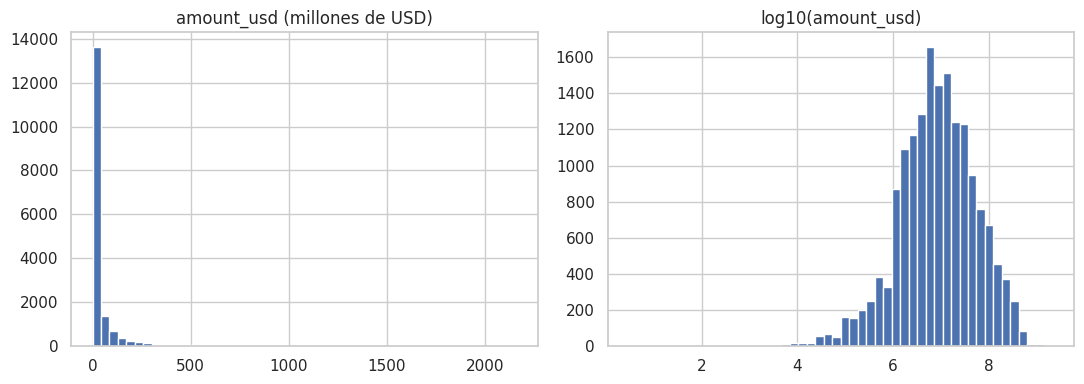

In [16]:
target = df_clean["amount_usd"].dropna()
print(f"Asimetría amount_usd: {target.skew():.2f} | log_amount: {df_clean['log_amount'].skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(target / 1e6, bins=50)
axes[0].set_title("amount_usd (millones de USD)")
axes[1].hist(df_clean["log_amount"].dropna(), bins=50)
axes[1].set_title("log10(amount_usd)")
plt.tight_layout()
plt.show()

## 2.5 Análisis exploratorio

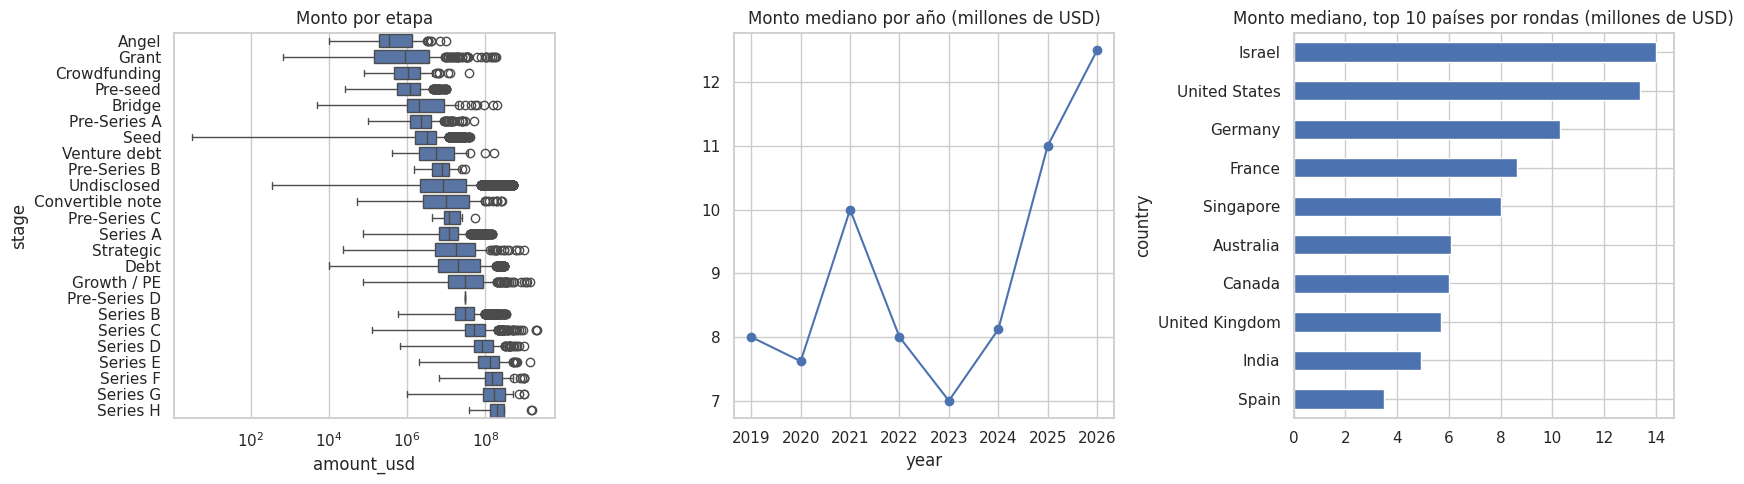

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

order = df_clean.groupby("stage")["amount_usd"].median().sort_values().index
sns.boxplot(data=df_clean, y="stage", x="amount_usd", order=order, ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_title("Monto por etapa")

df_clean.groupby("year")["amount_usd"].median().div(1e6).plot(marker="o", ax=axes[1])
axes[1].set_title("Monto mediano por año (millones de USD)")

top_countries = df_clean["country"].value_counts().head(10).index
df_clean[df_clean["country"].isin(top_countries)].groupby("country")["amount_usd"].median().div(1e6).sort_values().plot.barh(ax=axes[2])
axes[2].set_title("Monto mediano, top 10 países por rondas (millones de USD)")

plt.tight_layout()
plt.show()

Matriz de correlación entre las variables numéricas y el objetivo (Spearman, porque el monto es muy asimétrico y hay variables discretas).

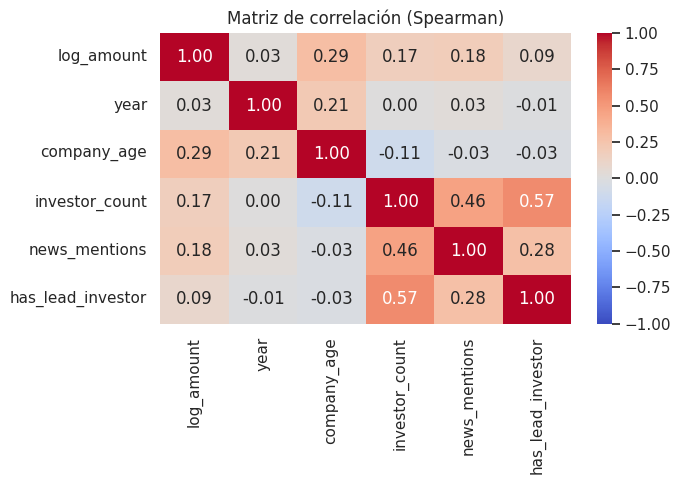

year                 0.030
has_lead_investor    0.091
investor_count       0.167
news_mentions        0.183
company_age          0.291


In [18]:
corr_cols = ["log_amount", "year", "company_age", "investor_count", "news_mentions", "has_lead_investor"]
corr = df_clean[corr_cols].astype(float).corr(method="spearman")

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación (Spearman)")
plt.tight_layout()
plt.show()
print(corr["log_amount"].drop("log_amount").sort_values().round(3).to_string())

## 2.6 Partición y transformación

Decisiones tomadas (valores recomendados, ajustables):
1. **Filas de entrenamiento:** solo rondas con monto conocido y `amount_status == "verified"`, sin los montos sospechosos (< 1.000 USD). Los outliers altos se conservan: son rondas reales y el logaritmo reduce su peso.
2. **Variables:** las básicas (etapa, sector, país, año, antigüedad, inversores) más el **historial de la empresa** (rondas previas y último monto conocido), la **popularidad del inversor líder** y el orden de la etapa. Se descartan ids y URLs.
3. **`news_excerpt` queda fuera a propósito:** en 62 % de las rondas el monto real está escrito en ese texto, así que usarlo sería leer la respuesta y no predecirla.
4. **Partición estratificada:** 80 % train y 20 % test, antes de transformar, estratificando por **deciles del monto** (`log10`). Así train y test tienen la misma distribución del objetivo. La validación cruzada también se estratifica igual. En una prueba con 10 semillas el R² fue el mismo con y sin estratificar (0,617 frente a 0,618): se usa por buena práctica, no porque suba el puntaje.
5. **Empresas repetidas:** se comprobó con validación agrupada por empresa que repetir empresas entre train y test no infla el resultado (R² 0,605 contra 0,607).
6. **Transformación:** dentro de un `Pipeline`, así en la validación cruzada se reajusta en cada pliegue. Las categorías con muchos valores (inversor líder, ciudad, fuente de la noticia) usan `TargetEncoder`.

In [19]:
usable = (
    (df_clean["amount_status"] == "verified")
    & df_clean["amount_usd"].notna()
    & ~df_clean["amount_suspect_low"]
)
cols_num = ["year", "company_age", "investor_count", "news_mentions", "has_lead_investor", "has_news",
            "n_prev_rounds", "prev_log_amount", "days_since_prev", "lead_freq", "stage_rank"]
cols_cat = ["stage", "sector", "country", "city", "lead_investor", "news_source"]

X = df_clean.loc[usable, cols_num + cols_cat]
y = df_clean.loc[usable, "log_amount"]

# Partición estratificada: 10 tramos (deciles) del monto, así train y test tienen la misma distribución del objetivo
estratos = pd.qcut(y, q=10, labels=False)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA, stratify=estratos)
print(f"Filas usables: {len(X):,} de {len(df_clean):,} | Train: {X_train.shape} | Test: {X_test.shape}")
print(f"log10(monto) medio: train {y_train.mean():.3f} | test {y_test.mean():.3f}")

# Numéricas: nulos -> mediana (con indicador de nulo) y escalado.
# Categóricas: TargetEncoder (cada categoría -> monto medio de su grupo), apto para muchas categorías como inversor o ciudad.
transformer = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)), ("scaler", StandardScaler())]), cols_num),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
                      ("target_enc", TargetEncoder(random_state=SEMILLA))]), cols_cat),
])
print("Columnas tras la transformación:", len(clone(transformer).fit(X_train, y_train).get_feature_names_out()))

Filas usables: 15,948 de 20,227 | Train: (12758, 17) | Test: (3190, 17)
log10(monto) medio: train 6.926 | test 6.929
Columnas tras la transformación: 21


## 2.7 Selección de variables (prueba de ablación)

Se entrena el modelo con las 17 variables y luego se quita **una a una**, midiendo el R² en validación cruzada (solo train). Si al quitarla el R² no baja, la variable no aporta y se descarta: menos ruido y un modelo más simple. Es la forma de "jugar con los valores de entrada".

In [20]:
def make_transformer(num, cat):
    return ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)), ("scaler", StandardScaler())]), num),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
                          ("target_enc", TargetEncoder(random_state=SEMILLA))]), cat),
    ])

# Validación cruzada estratificada por deciles del monto. Se guardan los pliegues como lista
# porque StratifiedKFold necesita clases y el objetivo es continuo; la lista sirve en cross_validate y en las búsquedas.
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
          .split(X_train, pd.qcut(y_train, q=10, labels=False)))

def cv_r2(num, cat):
    pipe = Pipeline([("prep", make_transformer(num, cat)), ("model", HistGradientBoostingRegressor(random_state=SEMILLA))])
    pred = cross_val_predict(pipe, X_train[num + cat], y_train, cv=cv, n_jobs=-1)
    return r2_score(y_train, pred)

r2_all = cv_r2(cols_num, cols_cat)
rows = []
for var in cols_num + cols_cat:
    r2 = cv_r2([c for c in cols_num if c != var], [c for c in cols_cat if c != var])
    rows.append((var, r2, r2_all - r2))   # cambio > 0: quitar la variable EMPEORA el modelo

ablation = pd.DataFrame(rows, columns=["variable", "R2_sin_ella", "aporte"]).sort_values("aporte", ascending=False).reset_index(drop=True)
print(f"R2 con las 17 variables: {r2_all:.4f}\n")
print(ablation.round(4).to_string())

R2 con las 17 variables: 0.6105

             variable  R2_sin_ella  aporte
0       lead_investor       0.5768  0.0337
1     prev_log_amount       0.5828  0.0278
2         company_age       0.5975  0.0130
3              sector       0.6002  0.0103
4      investor_count       0.6010  0.0095
5         news_source       0.6033  0.0072
6             country       0.6038  0.0067
7               stage       0.6044  0.0061
8       news_mentions       0.6050  0.0055
9          stage_rank       0.6063  0.0042
10               year       0.6066  0.0040
11               city       0.6073  0.0032
12      n_prev_rounds       0.6076  0.0029
13          lead_freq       0.6089  0.0016
14           has_news       0.6097  0.0008
15    days_since_prev       0.6104  0.0002
16  has_lead_investor       0.6105  0.0000


## 2.8 Variables finales

Se prueban tres conjuntos y se elige el de mejor R² en validación cruzada. Una diferencia menor a 0,0015 de R² está dentro del ruido de la validación cruzada, y en ese caso gana el conjunto más pequeño.

- **Todas:** las 17 variables.
- **Sin las débiles:** se quitan las que aportan menos de 0,0015 de R² en la ablación de 2.7.
- **Sin las 4 más débiles:** `days_since_prev`, `has_news`, `n_prev_rounds`, `lead_freq` (el conjunto elegido en una versión anterior con partición sin estratificar).

**Resultado:** se eligen **14 variables**: se descartan `has_news`, `days_since_prev` y `has_lead_investor` (esta última repite la información de `lead_investor`, que ya marca los nulos como "Unknown").

Conclusión: quitar variables **no sube** el puntaje; solo simplifica el modelo sin perder exactitud. Lo que limita el R² es la información que el dataset no trae (valuación e inversores completos), no las variables de entrada.

`news_mentions` y `news_source` salen de la noticia publicada **después** del anuncio. Se conservan porque quitarlas cuesta solo unos 0,01 de R²; si el modelo debe usarse **antes** de que se publique la noticia, hay que quitarlas.

In [21]:
weak = ablation.loc[ablation["aporte"] < 0.0015, "variable"].tolist()
low4 = ["days_since_prev", "has_news", "n_prev_rounds", "lead_freq"]
candidates = {"Todas (17)": [], f"Sin las débiles ({17 - len(weak)})": weak, "Sin las 4 más débiles (13)": low4}

res = {}
for name, drop in candidates.items():
    res[name] = cv_r2([c for c in cols_num if c not in drop], [c for c in cols_cat if c not in drop])
    print(f"{name:<32} R2 = {res[name]:.4f}")

# Diferencias menores a 0.0015 de R2 están dentro del ruido de la validación cruzada: gana el conjunto más pequeño
TOLERANCIA = 0.0015
best = max(res.values())
elegido = max((n for n in res if res[n] >= best - TOLERANCIA), key=lambda n: len(candidates[n]))
drop = candidates[elegido]
print("\nElegido:", elegido)

cols_num = [c for c in cols_num if c not in drop]
cols_cat = [c for c in cols_cat if c not in drop]
transformer = make_transformer(cols_num, cols_cat)
X = df_clean.loc[usable, cols_num + cols_cat]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA, stratify=estratos)  # mismas filas que en 2.6
print(f"{len(cols_num + cols_cat)} variables | numéricas: {cols_num}\ncategóricas: {cols_cat}")

Todas (17)                       R2 = 0.6105
Sin las débiles (14)             R2 = 0.6091
Sin las 4 más débiles (13)       R2 = 0.6076

Elegido: Sin las débiles (14)
14 variables | numéricas: ['year', 'company_age', 'investor_count', 'news_mentions', 'n_prev_rounds', 'prev_log_amount', 'lead_freq', 'stage_rank']
categóricas: ['stage', 'sector', 'country', 'city', 'lead_investor', 'news_source']


# 3. Ingeniería de modelos

## 3.1 Comparación de modelos (validación cruzada de 5 pliegues, solo train)

El transformador va dentro del `Pipeline`: en cada pliegue se ajusta solo con sus datos de entrenamiento.

                    modelo  MAE_log  std_MAE      R2
0              Extra Trees   0.3583   0.0056  0.6084
1   Hist Gradient Boosting   0.3605   0.0069  0.6088
2            Random Forest   0.3651   0.0067  0.5970
3       Red neuronal (512)   0.3668   0.0077  0.5979
4        Gradient Boosting   0.3677   0.0072  0.5967
5                      KNN   0.3898   0.0086  0.5516
6                    Lasso   0.3960   0.0086  0.5476
7               ElasticNet   0.3961   0.0085  0.5477
8                    Ridge   0.3964   0.0084  0.5478
9         Regresión lineal   0.3964   0.0084  0.5478
10       Árbol de decisión   0.3988   0.0070  0.5271
11                AdaBoost   0.4409   0.0091  0.4595
12          Base (mediana)   0.6337   0.0052 -0.0012


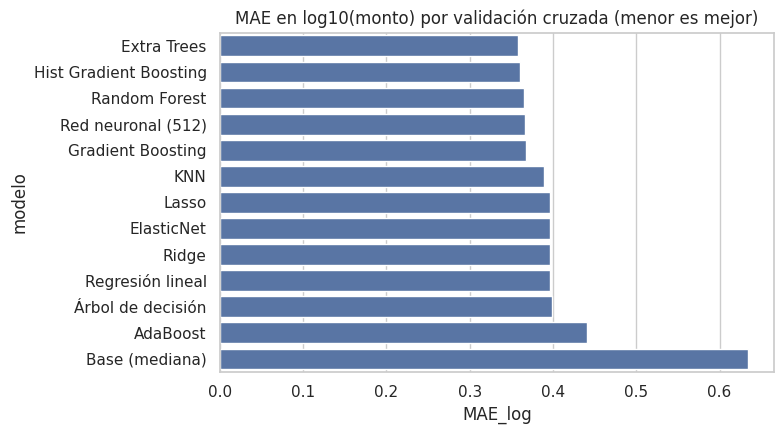

In [22]:
# Red neuronal: se detiene sola cuando la validación interna (10 % del train) no mejora en 10 épocas seguidas
# y se queda con los pesos de la mejor época. max_iter es solo un tope de seguridad (nunca se alcanza).
MLP_KWARGS = dict(alpha=0.01, early_stopping=True, n_iter_no_change=10, max_iter=1000)

def make_mlp(layers, seed=SEMILLA):
    # Se reescala porque el TargetEncoder no deja las columnas en la misma escala
    return Pipeline([("scaler", StandardScaler()), ("mlp", MLPRegressor(hidden_layer_sizes=layers, random_state=seed, **MLP_KWARGS))])

models = {
    "Base (mediana)": DummyRegressor(strategy="median"),
    "Regresión lineal": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.001),
    "ElasticNet": ElasticNet(alpha=0.001, l1_ratio=0.5),
    "KNN": KNeighborsRegressor(n_neighbors=15),
    "Árbol de decisión": DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=SEMILLA),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=SEMILLA),
    "Extra Trees": ExtraTreesRegressor(n_estimators=200, min_samples_leaf=2, random_state=SEMILLA),
    "Gradient Boosting": GradientBoostingRegressor(random_state=SEMILLA),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=SEMILLA),
    "AdaBoost": AdaBoostRegressor(random_state=SEMILLA),
    "Red neuronal (512)": make_mlp((512,)),
}

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", clone(transformer)), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["neg_mean_absolute_error", "r2"], n_jobs=-1)
    rows.append([name, -scores["test_neg_mean_absolute_error"].mean(), scores["test_neg_mean_absolute_error"].std(), scores["test_r2"].mean()])

table = pd.DataFrame(rows, columns=["modelo", "MAE_log", "std_MAE", "R2"]).sort_values("MAE_log").reset_index(drop=True)
print(table.round(4).to_string())

plt.figure(figsize=(8, 4.5))
sns.barplot(data=table, y="modelo", x="MAE_log", color="#4C72B0")
plt.title("MAE en log10(monto) por validación cruzada (menor es mejor)")
plt.tight_layout()
plt.show()

## 3.1b Redes neuronales: tamaño y número de capas

Se comparan 4 arquitecturas con **3 semillas** cada una (una sola semilla engaña: el ruido entre semillas es parecido a la diferencia entre redes). Se reporta también cuántas **épocas** entrenó cada red: la parada temprana decide cuántas y solo se guarda la mejor época, lo que evita el sobreajuste.

**Lectura de la tabla:**
- **Una capa de 512 neuronas es la mejor** (R² 0,596), pero la diferencia con 128 (0,589) y 32 (0,586) es pequeña: más neuronas ayudan poco.
- **Más capas no ayudan:** (512, 256, 128) tiene 172.672 pesos, unas 19 veces más que (512,), y rinde peor (0,584). Con 12.758 filas de entrenamiento, una red mayor se sobreajusta.
- **Épocas:** cuanto más grande la red, menos épocas necesita antes de que la validación deje de mejorar: 140 (32 neuronas), 81 (128), 56 (512) y 29 (tres capas). La parada temprana, y no un número fijo de épocas, es lo que controla el sobreajuste.
- **Ninguna red supera a los árboles** (Hist Gradient Boosting, R² 0,609 en validación cruzada).

In [23]:
configs = [(32,), (128,), (512,), (512, 256, 128)]
rows = []
for layers in configs:
    r2s, maes, epochs = [], [], []
    for seed in (0, 1, 2):
        pipe = Pipeline([("prep", clone(transformer)), ("model", make_mlp(layers, seed))])
        res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["neg_mean_absolute_error", "r2"], n_jobs=-1, return_estimator=True)
        r2s.append(res["test_r2"].mean())
        maes.append(-res["test_neg_mean_absolute_error"].mean())
        epochs += [est.named_steps["model"].named_steps["mlp"].n_iter_ for est in res["estimator"]]
    n_params = sum(c.size for c in res["estimator"][0].named_steps["model"].named_steps["mlp"].coefs_)
    rows.append([str(layers), n_params, np.mean(maes), np.mean(r2s), np.std(r2s), np.mean(epochs), min(epochs), max(epochs)])

mlp_table = pd.DataFrame(rows, columns=["capas", "pesos", "MAE_log", "R2_medio", "R2_std_semillas", "épocas_medias", "épocas_min", "épocas_max"])
print(mlp_table.round(4).to_string())

             capas   pesos  MAE_log  R2_medio  R2_std_semillas  épocas_medias  épocas_min  épocas_max
0            (32,)     576   0.3744    0.5859           0.0015       139.5333         107         160
1           (128,)    2304   0.3721    0.5888           0.0027        80.6000          64          94
2           (512,)    9216   0.3687    0.5958           0.0028        55.6667          45          86
3  (512, 256, 128)  172672   0.3755    0.5835           0.0021        28.6000          22          38


## 3.2 Ajuste de hiperparámetros: GridSearch vs RandomizedSearch

Se ajusta Hist Gradient Boosting con los dos métodos sobre train y se comparan:

- **GridSearchCV** prueba **todas** las combinaciones de una malla pequeña (24).
- **RandomizedSearchCV** prueba 20 combinaciones al azar de una malla más amplia (incluye `l2_regularization` y más hojas).

Se queda con el de mejor MAE en validación cruzada; si la diferencia es menor a 0,0005, gana la búsqueda exhaustiva. El prefijo `model__` indica que el parámetro pertenece al paso `model` del `Pipeline`.

In [24]:
base = Pipeline([("prep", clone(transformer)), ("model", HistGradientBoostingRegressor(random_state=SEMILLA))])

param_grid = {
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_iter": [200, 400],
    "model__max_leaf_nodes": [15, 31],
    "model__min_samples_leaf": [10, 40],
}
param_dist = {
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_iter": [200, 400],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [10, 20, 40],
    "model__l2_regularization": [0, 1, 10],
}
grid = GridSearchCV(base, param_grid, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1).fit(X_train, y_train)
random_search = RandomizedSearchCV(base, param_dist, n_iter=20, cv=cv, scoring="neg_mean_absolute_error",
                                   random_state=SEMILLA, n_jobs=-1).fit(X_train, y_train)

mae_before = table.loc[table["modelo"] == "Hist Gradient Boosting", "MAE_log"].iloc[0]
comparison = pd.DataFrame({
    "combinaciones": [1, len(grid.cv_results_["params"]), len(random_search.cv_results_["params"])],
    "MAE_log_cv": [mae_before, -grid.best_score_, -random_search.best_score_],
}, index=["Sin ajuste", "GridSearch", "RandomizedSearch"])
print(comparison.round(4).to_string())

# Gana la búsqueda exhaustiva salvo que la aleatoria sea mejor por más de 0.0005
if -grid.best_score_ <= -random_search.best_score_ + 0.0005:
    search, metodo = grid, "GridSearch"
else:
    search, metodo = random_search, "RandomizedSearch"
final_model = search.best_estimator_
print("\nElegido:", metodo)
print("Mejores parámetros:", search.best_params_)

                  combinaciones  MAE_log_cv
Sin ajuste                    1      0.3605
GridSearch                   24      0.3599
RandomizedSearch             20      0.3595

Elegido: GridSearch
Mejores parámetros: {'model__learning_rate': 0.03, 'model__max_iter': 400, 'model__max_leaf_nodes': 31, 'model__min_samples_leaf': 40}


# 4. Evaluación y aseguramiento de calidad

## 4.1 Evaluación en test (una sola vez)

Se compara contra predecir siempre la mediana de train, y se revisan los criterios de aceptación fijados en 1.2 (R² ≥ 0,55 y MAE en log10 ≤ 0,40).

In [25]:
final_model.fit(X_train, y_train)
pred_log = final_model.predict(X_test)
baseline_log = np.full(len(y_test), y_train.median())

def report(true_log, est_log):
    real, est = 10 ** true_log, 10 ** est_log
    ape = np.abs(est - real) / real
    return {
        "R2": r2_score(true_log, est_log),
        "MAE_log": mean_absolute_error(true_log, est_log),
        "RMSE_log": np.sqrt(mean_squared_error(true_log, est_log)),
        "MdAPE": np.median(ape),
        "cobertura": (ape <= BANDA).mean(),
        "pct_sobreestima": (est > real).mean(),
    }

results = pd.DataFrame({
    "Base (mediana)": report(y_test.values, baseline_log),
    "Hist Gradient Boosting": report(y_test.values, pred_log),
}).T
results["cumple"] = (results["R2"] >= R2_MIN) & (results["MAE_log"] <= MAE_LOG_MAX)
results.round(3)

,R2,MAE_log,RMSE_log,MdAPE,cobertura,pct_sobreestima,cumple
Base (mediana),-0.001,0.629,0.798,0.850,0.226,0.497,False
Hist Gradient Boosting,0.615,0.350,0.495,0.529,0.473,0.510,True


## 4.2 Errores del modelo

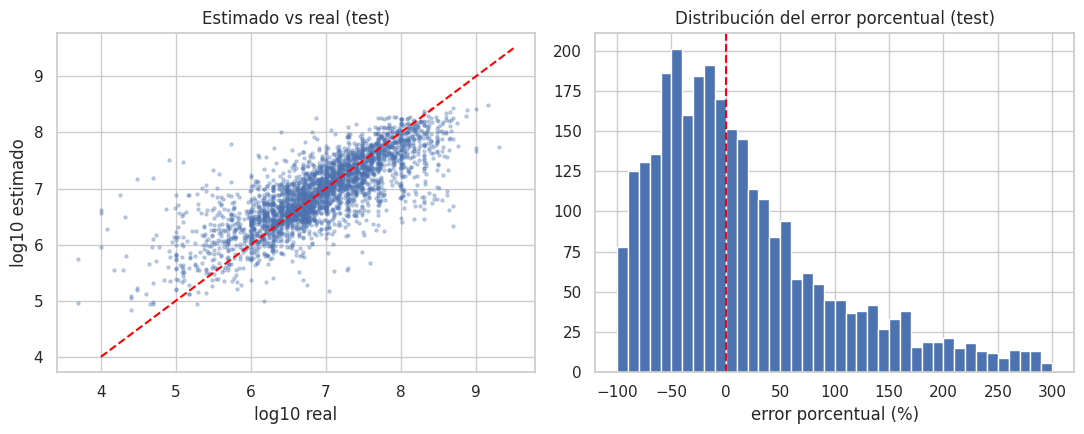

,n,MdAPE,pct_sobreestima
stage,,,
Series A,535,0.401,0.521
Series B,304,0.411,0.520
Pre-seed,117,0.411,0.530
Series C,144,0.414,0.549
Pre-Series A,64,0.433,0.484
Series D,72,0.439,0.583
Seed,585,0.492,0.506
Growth / PE,75,0.623,0.547
Undisclosed,1001,0.711,0.512


In [26]:
real, est = 10 ** y_test.values, 10 ** pred_log
ape = np.abs(est - real) / real

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(y_test, pred_log, s=5, alpha=0.3)
axes[0].plot([4, 9.5], [4, 9.5], color="red", linestyle="--")
axes[0].set_xlabel("log10 real")
axes[0].set_ylabel("log10 estimado")
axes[0].set_title("Estimado vs real (test)")
axes[1].hist((est - real) / real * 100, bins=np.arange(-100, 301, 10))
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("error porcentual (%)")
axes[1].set_title("Distribución del error porcentual (test)")
plt.tight_layout()
plt.show()

# Error por etapa: dónde falla más el modelo
by_stage = (
    pd.DataFrame({"stage": X_test["stage"].values, "ape": ape, "sobre": est > real})
    .groupby("stage").agg(n=("ape", "size"), MdAPE=("ape", "median"), pct_sobreestima=("sobre", "mean"))
    .query("n >= 30").sort_values("MdAPE")
)
by_stage.round(3)

Lectura: el error es menor en las rondas con etapa conocida de Series A a D y Pre-seed (MdAPE entre 40 % y 44 %) y sube en Seed (49 %), `Undisclosed` (71 %, casi un tercio del test), `Debt` (71 %) y `Grant` (77 %). La etapa es la variable que más explica el monto, y en esas filas no informa.

## 4.3 Importancia de variables, calculada en una validación interna de train

El test queda solo para la evaluación final.

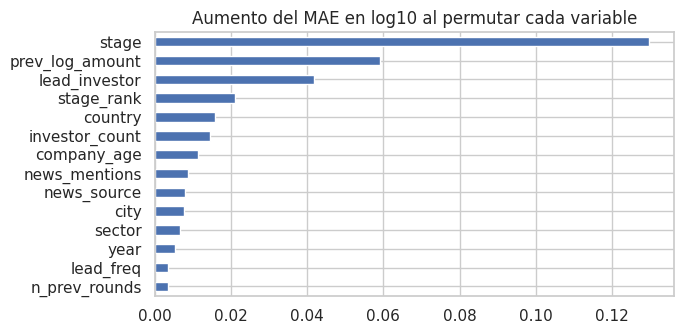

stage              0.1298
prev_log_amount    0.0590
lead_investor      0.0418
stage_rank         0.0209
country            0.0159
investor_count     0.0145
company_age        0.0114
news_mentions      0.0087
news_source        0.0080
city               0.0077
sector             0.0065
year               0.0051
lead_freq          0.0035
n_prev_rounds      0.0033


In [27]:
X_sub, X_val, y_sub, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=SEMILLA)
imp = permutation_importance(clone(final_model).fit(X_sub, y_sub), X_val, y_val,
                             scoring="neg_mean_absolute_error", n_repeats=5, random_state=SEMILLA)
importances = pd.Series(imp.importances_mean, index=X_val.columns).sort_values()
importances.plot.barh(title="Aumento del MAE en log10 al permutar cada variable", figsize=(7, 3.5))
plt.tight_layout()
plt.show()
print(importances.sort_values(ascending=False).round(4).to_string())

## 4.4 Casos límite de entrada (QA)

Prueba de funcionamiento con valores extremos, una categoría desconocida y un nulo. No mide exactitud: solo detecta fallos de inferencia o salidas inválidas.

In [28]:
edge = X_train.iloc[:3].copy()
edge.iloc[0, edge.columns.get_loc("company_age")] = 40
edge.iloc[1, edge.columns.get_loc("investor_count")] = 100
edge.iloc[2, edge.columns.get_loc("country")] = "País no observado"
edge.iloc[2, edge.columns.get_loc("sector")] = np.nan

amounts = 10 ** final_model.predict(edge)
assert np.isfinite(amounts).all() and (amounts > 0).all()
pd.DataFrame({"caso": ["antigüedad alta", "muchos inversores", "país desconocido y sector nulo"],
              "monto_estimado_usd": amounts.round(-3)})

,caso,monto_estimado_usd
0,antigüedad alta,17308000.0
1,muchos inversores,38262000.0
2,país desconocido y sector nulo,67328000.0


# 5. Despliegue

Se guarda solo el **modelo final** (Hist Gradient Boosting ajustado) en `modelo_rondas.joblib`, descargable desde el panel de archivos de Colab. Contiene el pipeline completo, las columnas, las restricciones, los parámetros y las métricas de test.

Se prueba la carga del archivo. Requiere la misma versión de scikit-learn con la que se guardó.

In [29]:
artifact = {
    "pipeline": final_model,
    "columns": list(X_train.columns),
    "criterios": {"r2_min": R2_MIN, "mae_log_max": MAE_LOG_MAX},
    "metricas_test": results.loc["Hist Gradient Boosting"].to_dict(),
    "parametros": search.best_params_,
    # Tablas que la API necesita para calcular las variables igual que en el entrenamiento
    "lead_freq_map": df_clean["lead_investor"].value_counts().to_dict(),   # inversor -> número de rondas como líder
    "stage_rank_map": stage_rank,
}
joblib.dump(artifact, "modelo_rondas.joblib")

# Prueba de carga con 8 rondas del test
loaded = joblib.load("modelo_rondas.joblib")
sample = X_test.head(8)
demo = sample[["stage", "sector", "country"]].copy()
demo["monto_estimado_usd"] = (10 ** loaded["pipeline"].predict(sample[loaded["columns"]])).round(-3)
demo["monto_real_usd"] = (10 ** y_test.head(8)).round(-3)
demo

,stage,sector,country,monto_estimado_usd,monto_real_usd
18181,Pre-seed,Enterprise Infrastructure,United States,616000.0,400000.0
17213,Undisclosed,Healthcare,United States,5828000.0,15000000.0
12435,Pre-seed,Edtech,Ireland,592000.0,5100000.0
18050,Undisclosed,Fintech,Spain,40001000.0,320000000.0
17937,Series B,Business Services,United States,52608000.0,49800000.0
7512,Series C,Enterprise Applications,United States,52704000.0,40000000.0
4350,Debt,Fintech,India,92685000.0,90000000.0
16394,Undisclosed,Consumer,India,2014000.0,4690000.0


# 6. Monitoreo y mantenimiento

PSI de las variables numéricas de entrada: menos de 0,10 estable, entre 0,10 y 0,25 cambio moderado, más de 0,25 cambio fuerte.

| Señal | Acción |
|---|---|
| PSI entre 0,10 y 0,25 en una variable | Revisar la fuente de datos y vigilar el indicador el mes siguiente |
| PSI mayor a 0,25 | Verificar que no sea un error de captura; si el mercado cambió de verdad, reentrenar con datos recientes |
| R² bajo 0,55 o MAE en log10 sobre 0,40 con montos reales nuevos | Dejar de usar la estimación sin revisión humana y reentrenar |
| Muchas rondas nuevas con etapa `Undisclosed` | Es donde el modelo falla más: tratar esas estimaciones como poco fiables |
| Sin alertas | Reentrenar de todos modos cada 6 meses |

In [30]:
def psi(ref, new, bins=10):
    cuts = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    cuts[0], cuts[-1] = -np.inf, np.inf
    r = np.clip(np.histogram(ref, cuts)[0] / len(ref), 1e-4, None)
    n = np.clip(np.histogram(new, cuts)[0] / len(new), 1e-4, None)
    return np.sum((n - r) * np.log(n / r))

# Referencia: train. Comparación: test (sin cambio) y un escenario simulado de deriva
scenario = X_test.assign(company_age=X_test["company_age"] + 3, investor_count=X_test["investor_count"] * 2 + 1)
psi_table = pd.DataFrame({
    "PSI_test": {c: psi(X_train[c], X_test[c]) for c in cols_num},
    "PSI_escenario": {c: psi(X_train[c], scenario[c]) for c in cols_num},
})
print(psi_table.round(3).to_string())
print("Monto estimado mediano, test:", round(np.median(10 ** final_model.predict(X_test))))
print("Monto estimado mediano, escenario:", round(np.median(10 ** final_model.predict(scenario))))

                 PSI_test  PSI_escenario
year                0.007          0.007
company_age         0.003          1.807
investor_count      0.005          2.942
news_mentions       0.001          0.001
n_prev_rounds       0.000          0.000
prev_log_amount     0.000          0.000
lead_freq           0.000          0.000
stage_rank          0.000          0.000
Monto estimado mediano, test: 8857696
Monto estimado mediano, escenario: 10231042


# 7. Resumen final

In [31]:
print(f"Modelo final: Hist Gradient Boosting ({metodo}) |", search.best_params_)
print(f"Variables: {len(cols_num + cols_cat)} | Datos: {len(X):,} rondas verificadas | Train {len(X_train):,} | Test {len(X_test):,}")
print(results.round(3).to_string())
print("\nMejora frente a la base: el MAE en log10 baja de",
      round(results.loc["Base (mediana)", "MAE_log"], 3), "a", round(results.loc["Hist Gradient Boosting", "MAE_log"], 3))
print("Cumple las restricciones:", bool(results.loc["Hist Gradient Boosting", "cumple"]))

Modelo final: Hist Gradient Boosting (GridSearch) | {'model__learning_rate': 0.03, 'model__max_iter': 400, 'model__max_leaf_nodes': 31, 'model__min_samples_leaf': 40}
Variables: 14 | Datos: 15,948 rondas verificadas | Train 12,758 | Test 3,190
                           R2  MAE_log  RMSE_log  MdAPE  cobertura  pct_sobreestima  cumple
Base (mediana)         -0.001    0.629     0.798  0.850      0.226            0.497   False
Hist Gradient Boosting  0.615    0.350     0.495  0.529      0.473            0.510    True

Mejora frente a la base: el MAE en log10 baja de 0.629 a 0.35
Cumple las restricciones: True
